# Lab 1: The PyTorch training loop

Every model you will train in this course, from a small MLP to an autoencoder, is trained by the same few lines of code: the **training loop**. The goal of today's lab is to write that loop ourselves, one piece at a time, so that by the end we have a single `fit` function that can train any classifier we give it.

We will use it on MNIST to train an MLP and then a CNN without changing a line of the loop, and finally we will use it to tune the hyperparameters of the MLP.

## Before you start

The notebook uses files from the course repository (the figures in `notebooks_imgs/`), so clone the whole repository instead of downloading the notebook alone:

```bash
git clone <REPO_URL> mdmc_dl_hands_on
cd mdmc_dl_hands_on
jupyter lab
```

On Google Colab, run `!git clone <REPO_URL> mdmc_dl_hands_on` and `%cd mdmc_dl_hands_on` in a cell first, and enable a GPU from `Runtime > Change runtime type`. On Colab you can run shell commands by prefixing them with `!` (e.g. `!nvidia-smi`), and you can mount your Google Drive with `from google.colab import drive; drive.mount('/content/drive')` if you want to keep files after the session ends.

This is the solved version of the lab. Run the cells in order: later cells use what earlier cells define. Your numbers will differ slightly from the ones quoted in the text because of random initialization and shuffling.

## The plan

Here is the whole training procedure in pseudo code. Each section of the notebook implements one numbered block, and the sections are in the same order.

```
1. data       split the dataset into train / validation / test, wrap them in DataLoaders
2. model      a network mapping a batch of images to 10 scores (one per digit)
3. loss       a function measuring how wrong the scores are
4. optimizer  a rule that updates the weights using the gradients of the loss

5. for each epoch:
       for each mini-batch (x, y) in the training set:
           scores = model(x)                      # forward pass
           loss   = loss_fn(scores, y)
           reset the gradients
           compute the gradients of the loss      # backward pass
           update the weights
6.     evaluate the model on the validation set

7. evaluate the final model once on the test set
```

Blocks 1-4 are the ingredients; blocks 5-7 are the loop itself. Notice that the loop never looks inside the model: it only calls `model(x)`. This is what will let us swap the MLP for a CNN later on.

In [1]:
import copy
import itertools

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision.datasets import MNIST
from torchvision.transforms import v2
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from collections import defaultdict

from sklearn.model_selection import KFold
from torch.utils.data import Subset
from tqdm.auto import tqdm

# use the best available device: NVIDIA GPU (cuda) > Apple Silicon GPU (mps) > CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Using device:", DEVICE)

Using device: cuda


/home/egoat/Desktop/mdmc_dl_hands_on/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


A note on devices: the model and the data must live on the same device. We move the model once with `model.to(DEVICE)`, and every mini-batch with `x.to(DEVICE)` inside the loop. Anything that goes to NumPy, scikit-learn or matplotlib has to come back with `.cpu()`.

# 1. Data

```
1. data       split the dataset into train / validation / test, wrap them in DataLoaders
```

We use [MNIST](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html): $28 \times 28$ grayscale images of handwritten digits, 60k for training and 10k for testing. It is an easy dataset, which lets us focus on the loop rather than on the data.

## Transforms and normalization

A [transform](https://docs.pytorch.org/vision/stable/transforms.html) is applied to every image when it is read from the dataset. `v2.Compose([...])` chains several of them:

| Transform | Result on an MNIST image |
|---|---|
| `v2.ToImage()` | `uint8` tensor of shape `(1, 28, 28)`, values in $\{0, \dots, 255\}$ |
| `v2.ToDtype(torch.float32, scale=True)` | `float32`, values in $[0, 1]$ |
| `v2.Normalize(mean, std)` | $x' = (x - \text{mean}) / \text{std}$, so pixels have mean $\approx 0$ and std $\approx 1$ |

Networks train faster and more stably when inputs are centred and of unit scale. The mean and std must be computed on the **training set only**: the test set should not influence anything we do before the final evaluation.

**Exercise.** Complete `normalization_values`: `images` has shape `(n_samples, channels, height, width)`; return the mean and std of the pixels for each channel, i.e. two tensors of shape `(channels,)`. Then build the first two transforms and compute the values on the training set (expected: mean $\approx 0.13$, std $\approx 0.31$).

In [2]:
def normalization_values(dataset, n_samples=10_000):
    # Mean and std of the pixels, per channel, estimated on n_samples random images.
    idx = torch.randperm(len(dataset))[:n_samples]
    images = torch.stack([dataset[i][0] for i in idx])        # (n_samples, C, H, W)
    # reduce over samples, height and width: only the channel dimension stays
    return images.mean(dim=(0, 2, 3)), images.std(dim=(0, 2, 3))


to_tensor = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])
mnist_train = MNIST("datasets", train=True, download=True, transform=to_tensor)

mean, std = normalization_values(mnist_train)
print(f"mean: {mean.item():.4f}  std: {std.item():.4f}")

mean: 0.1307  std: 0.3080


Now we load training and test set again, this time normalizing with these values. The test set gets exactly the same transforms, with the statistics of the training set.

In [3]:
transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std),
])
mnist_train = MNIST("datasets", train=True, download=True, transform=transforms)
mnist_test = MNIST("datasets", train=False, download=True, transform=transforms)

x = torch.stack([mnist_train[i][0] for i in range(2000)])
print(f"after normalization: mean {x.mean():.3f}, std {x.std():.3f}")

after normalization: mean -0.002, std 0.999


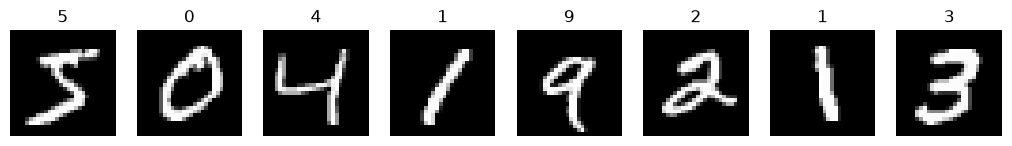

In [4]:
def plot_examples(dataset, n=8):
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2))
    for ax, i in zip(axes, range(n)):
        img, label = dataset[i]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(label)
        ax.set_axis_off()
    plt.show()


plot_examples(mnist_train)

## Train / validation / test

We need three sets with three different jobs:

- **training**: the model learns its weights on it;
- **validation**: we look at it during training and use it to choose hyperparameters (learning rate, network size, ...);
- **test**: used once, at the very end, to report how well the final model does on data it has never influenced.

MNIST only comes with train and test, so we carve a validation set (12k / 60k images) out of the training set. The fixed `generator` makes the split the same at every run.

In [5]:
train_set, val_set = random_split(mnist_train, [48_000, 12_000],
                                  generator=torch.Generator().manual_seed(0))
test_set = mnist_test
print(f"train: {len(train_set)}  val: {len(val_set)}  test: {len(test_set)}")

train: 48000  val: 12000  test: 10000


## DataLoaders

A `DataLoader` wraps a dataset and gives back mini-batches: iterating over it yields pairs `(x, y)` with `x` of shape `(batch_size, 1, 28, 28)` and `y` of shape `(batch_size,)`. The two parameters we care about are `batch_size` and `shuffle`.

The training loader should shuffle, so that every epoch sees the mini-batches in a different order and the model cannot exploit the order of the data. For validation and test the order does not change the result, so we keep it fixed.

**Exercise.** Complete `make_loaders`. We write it as a function because the batch size is itself a hyperparameter we may want to change later.

In [6]:
def make_loaders(train_set, val_set, test_set, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader


BATCH_SIZE = 32
train_loader, val_loader, test_loader = make_loaders(train_set, val_set, test_set, BATCH_SIZE)

x, y = next(iter(train_loader))
print("one mini-batch:", tuple(x.shape), tuple(y.shape))
assert x.shape == (BATCH_SIZE, 1, 28, 28) and y.shape == (BATCH_SIZE,)

one mini-batch: (32, 1, 28, 28) (32,)


# 2. Model

```
2. model      a network mapping a batch of images to 10 scores (one per digit)
```

A PyTorch model is a class inheriting from `torch.nn.Module`, with two methods: `__init__`, where we create the layers, and `forward`, where we say how the input flows through them. We never write the backward pass: autograd derives it from `forward`.

The only thing the training loop asks of a model is this contract: **input** a batch of shape `(batch, 1, 28, 28)`, **output** a tensor of shape `(batch, 10)`. Whatever happens in between is the model's business.

## The MLP

The basic block is `torch.nn.Linear(in_features, out_features)`, which computes $y = xW^T + b$ with $W$ of shape `(out_features, in_features)` and $b$ of shape `(out_features,)`. An MLP stacks a few of them, with a non-linear activation (here ReLU) between consecutive layers. Without the activations the whole stack would collapse into a single linear map.

<p align="center">
  <img src="../notebooks_imgs/mlp_with_nonlinear_activations.png" alt="MLP" width="500" style="background-color: white;"/>
</p>

**Exercise.** Complete the `MLP`:
- `__init__`: three `Linear` layers (`in_features` → `hidden1` → `hidden2` → `out_features`) and a `torch.nn.ReLU` activation;
- `forward`: flatten each image to a vector of 784 values with `x.reshape(x.shape[0], -1)`, then layer, ReLU, layer, ReLU, layer.

The last layer has no activation: it returns raw scores, called **logits**. The softmax is applied inside the loss (section 3). Note that the flattening happens inside the model, not in the loop: this is what keeps the loop model-agnostic.

In [7]:
class MLP(torch.nn.Module):
    def __init__(self, in_features=28 * 28, hidden1=64, hidden2=64, out_features=10):
        super().__init__()
        self.layer1 = torch.nn.Linear(in_features, hidden1)
        self.layer2 = torch.nn.Linear(hidden1, hidden2)
        self.layer3 = torch.nn.Linear(hidden2, out_features)
        self.activation = torch.nn.ReLU()

    def forward(self, x):
        x = x.reshape(x.shape[0], -1)          # (batch, 1, 28, 28) -> (batch, 784)
        x = self.activation(self.layer1(x))    # (batch, hidden1)
        x = self.activation(self.layer2(x))    # (batch, hidden2)
        return self.layer3(x)                  # (batch, 10), logits


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


model = MLP().to(DEVICE)
print(model)
print(f"parameters: {count_parameters(model):,}")
print("output shape:", model(torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE)).shape)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=64, bias=True)
  (layer3): Linear(in_features=64, out_features=10, bias=True)
  (activation): ReLU()
)
parameters: 55,050
output shape: torch.Size([32, 10])


The weights are stored in the model's `state_dict`, a dictionary indexed by the layer names we chose in `__init__`. Right now they are random: training is the process of changing them.

In [8]:
for name, param in model.state_dict().items():
    print(f"{name:15s} {tuple(param.shape)}")

layer1.weight   (64, 784)
layer1.bias     (64,)
layer2.weight   (64, 64)
layer2.bias     (64,)
layer3.weight   (10, 64)
layer3.bias     (10,)


# 3. Loss

```
3. loss       a function measuring how wrong the scores are
           ...
           loss   = loss_fn(scores, y)
```

For classification the standard choice is the cross-entropy. The model outputs $K = 10$ logits $z_1, \dots, z_K$; the softmax turns them into probabilities

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}},$$

and **the loss is minus the log-probability given to the correct class $y$, averaged over the mini-batch**:

$$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \log p_{i,\, y_i}.$$

It is small when the model is confident and right, and very large when it is confident and wrong:

| $p_y$ | $-\log p_y$ |
|---|---|
| 0.9 | 0.11 |
| 0.5 | 0.69 |
| 0.1 | 2.30 (random guess among 10 classes) |
| 0.01 | 4.61 |

A useful sanity check follows from the third row: an untrained network guesses roughly at random, so **its loss should start around $\ln 10 \approx 2.3$**.

`torch.nn.CrossEntropyLoss` takes the raw logits `(batch, K)` and the integer labels `(batch,)` and applies the softmax internally. That is why the model must not end with a softmax.

**Exercise.** Create `loss_fn`, then check on a small example that it matches the formula computed by hand.

In [9]:
loss_fn = torch.nn.CrossEntropyLoss()

logits = torch.tensor([[2.0, 0.5, -1.0]])    # one image, 3 classes
target = torch.tensor([0])                   # the correct class is 0

probs = torch.softmax(logits, dim=1)
print("by hand:          ", (-torch.log(probs[0, target[0]])).item())
print("CrossEntropyLoss: ", loss_fn(logits, target).item())

by hand:           0.24131131172180176
CrossEntropyLoss:  0.24131132662296295


In [10]:
# sanity check on a real mini-batch: the untrained MLP should give about ln(10) = 2.30
x, y = next(iter(train_loader))
with torch.no_grad():
    print(f"loss of the untrained model: {loss_fn(model(x.to(DEVICE)), y.to(DEVICE)).item():.3f}")

loss of the untrained model: 2.315


# 4. Optimizer

```
4. optimizer  a rule that updates the weights using the gradients of the loss
           ...
           reset the gradients
           compute the gradients of the loss      # backward pass
           update the weights
```

## Optimizers

Given the gradients, the optimizer decides how to change the weights. The simplest rule is (stochastic) gradient descent, with the gradient $g = \nabla_\theta \mathcal{L}$ computed on a mini-batch:

$$\theta \leftarrow \theta - \text{lr} \cdot g.$$

The learning rate `lr` is the most important hyperparameter of the whole procedure: too large and the loss oscillates or diverges, too small and training crawls. With **momentum** $\mu$ (typically 0.9) SGD keeps a running velocity $v \leftarrow \mu v + g$ and steps along $v$ instead of $g$, which smooths the zig-zag and speeds up progress along consistent directions.

`torch.optim` has all the common optimizers (`SGD`, `Adam`, `RMSprop`, ...). They all take the parameters to update, usually `model.parameters()`, and all expose the same two methods, which is all the loop needs:

- `optimizer.zero_grad()`: reset the gradients of all the parameters;
- `optimizer.step()`: update the parameters using their current `.grad`.

Between the two we call `loss.backward()` to fill in the gradients. `Adam` adapts a separate step size for every parameter and often works well with its default `lr=1e-3` without much tuning; we stick to SGD here, and you can try Adam in the homework.

**Exercise.** Create an SGD optimizer for `model.parameters()` with `lr=1e-2` and `momentum=0.9`. Then do a single training step by hand on one mini-batch and check that the loss on that batch goes down.

In [11]:
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

x, y = next(iter(train_loader))
x, y = x.to(DEVICE), y.to(DEVICE)

loss = loss_fn(model(x), y)
print(f"loss before the step: {loss.item():.4f}")

optimizer.zero_grad()
loss.backward()
optimizer.step()

with torch.no_grad():
    print(f"loss after the step:  {loss_fn(model(x), y).item():.4f}")

loss before the step: 2.3148
loss after the step:  2.3036


That cell already contains every line of the inner loop. What is left is to repeat it over all the mini-batches and all the epochs, and to measure how the model is doing.

# 5. One epoch of training

```
5. for each epoch:
       for each mini-batch (x, y) in the training set:
           scores = model(x)
           loss   = loss_fn(scores, y)
           reset the gradients
           compute the gradients of the loss
           update the weights
```

One pass over the whole training set is an **epoch**. We write the inner loop as a function, `train_one_epoch`, that takes everything it needs as arguments and returns the average training loss.

Two details:

- `model.train()` puts the model in training mode. Our MLP behaves the same in both modes, but layers such as dropout and batch normalization do not, so we always set the mode explicitly.
- `loss.item()` turns the 1-element loss tensor into a Python float. Accumulating the tensor itself would keep the whole computational graph of every batch in memory.

**Exercise.** Translate the pseudo code above into `train_one_epoch`. The order of the three optimizer calls matters.

In [12]:
def train_one_epoch(model, loader, loss_fn, optimizer, device=DEVICE):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        scores = model(x)              # forward pass
        loss = loss_fn(scores, y)      # loss function computation
        optimizer.zero_grad()          # reset the gradients
        loss.backward()                # backward pass
        optimizer.step()               # update the weights
        total_loss += loss.item()
    return total_loss / len(loader)    # len(loader) = number of mini-batches

# 6. Evaluation

```
6.     evaluate the model on the validation set
7. evaluate the final model once on the test set
```

Evaluating is the forward half of the training step: no gradients, no updates. We use the same function for validation (every epoch) and test (once at the end).

- `model.eval()` switches to evaluation mode (the counterpart of `model.train()`).
- `torch.no_grad()` tells autograd not to record anything: evaluation is faster, uses less memory, and cannot accidentally update the weights.
- The predicted class is the index of the largest logit, `scores.argmax(dim=1)`.
- `loss_fn` returns the mean over the batch. To average correctly over the whole dataset we multiply by the batch size before summing, since the last batch can be smaller.

**Exercise.** Complete `evaluate` so that it returns the average loss and the accuracy.

In [13]:
def evaluate(model, loader, loss_fn, device=DEVICE):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            scores = model(x)
            total_loss += loss_fn(scores, y).item() * len(y)
            correct += (scores.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n


# a fresh, untrained MLP should be at chance level: loss ~2.30, accuracy ~0.10
val_loss, val_acc = evaluate(MLP().to(DEVICE), val_loader, loss_fn)
print(f"untrained MLP: val loss {val_loss:.3f}, val accuracy {val_acc:.3f}")

untrained MLP: val loss 2.320, val accuracy 0.100


# 7. Putting it together: `fit`

We now have all the pieces, so the full procedure is short:

```
for each epoch:
    train_one_epoch(...)
    evaluate(...) on the validation set
```

`fit` runs it and records the losses and the accuracy of every epoch in a `history` dictionary, which we use for plotting and, later, for comparing hyperparameters. It does not create the model, the loss or the optimizer: they are passed in from outside. This separation is what makes the same function work for any model.

The validation loader is optional: at the end of the lab we will retrain on train + validation, and then there is nothing left to validate on.

**Exercise.** Complete `fit`.

In [14]:
def fit(model, train_loader, loss_fn, optimizer, n_epochs, val_loader=None, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        history["train_loss"].append(train_loss)
        msg = f"epoch {epoch}/{n_epochs}  train loss {train_loss:.4f}"

        if val_loader is not None:
            val_loss, val_acc = evaluate(model, val_loader, loss_fn)
            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)
            msg += f"  val loss {val_loss:.4f}  val acc {val_acc:.4f}"

        if verbose:
            print(msg)
    return history

## Training the MLP

Every block of the plan now fits in one cell. We create a fresh model (the one above already took a step) and train it for 5 epochs. The `torch.manual_seed` makes the initialization reproducible, which will matter when we compare models.

In [15]:
N_EPOCHS = 5

torch.manual_seed(0)
mlp = MLP().to(DEVICE)                                                    # 2. model
loss_fn = torch.nn.CrossEntropyLoss()                                     # 3. loss
optimizer = torch.optim.SGD(mlp.parameters(), lr=1e-2, momentum=0.9)      # 4. optimizer

mlp_history = fit(mlp, train_loader, loss_fn, optimizer, N_EPOCHS, val_loader)   # 5. + 6.

mlp_test_loss, mlp_test_acc = evaluate(mlp, test_loader, loss_fn)        # 7.
print(f"\nMLP test loss {mlp_test_loss:.4f}  test accuracy {mlp_test_acc:.4f}")

epoch 1/5  train loss 0.2899  val loss 0.1394  val acc 0.9584
epoch 2/5  train loss 0.1217  val loss 0.1235  val acc 0.9649
epoch 3/5  train loss 0.0912  val loss 0.1154  val acc 0.9670
epoch 4/5  train loss 0.0712  val loss 0.1169  val acc 0.9674
epoch 5/5  train loss 0.0585  val loss 0.1037  val acc 0.9714

MLP test loss 0.0948  test accuracy 0.9714


## Looking at the results

The training curves tell us whether training went well. The training loss should go down steadily. If the validation loss starts going up while the training loss keeps decreasing, the model is overfitting.

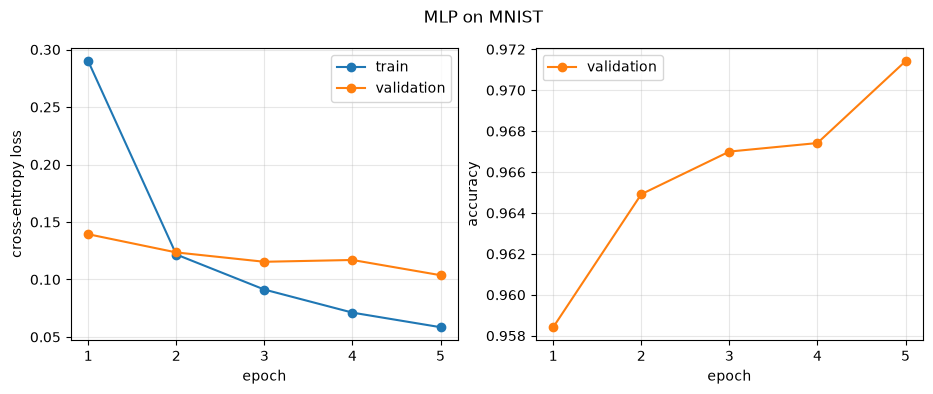

In [16]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))

    ax_loss.plot(epochs, history["train_loss"], marker="o", label="train")
    if history["val_loss"]:
        ax_loss.plot(epochs, history["val_loss"], marker="o", label="validation")
    ax_loss.set_ylabel("cross-entropy loss")

    if history["val_acc"]:
        ax_acc.plot(epochs, history["val_acc"], marker="o", color="C1", label="validation")
    ax_acc.set_ylabel("accuracy")

    for ax in (ax_loss, ax_acc):
        ax.set_xlabel("epoch")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.show()


plot_history(mlp_history, "MLP on MNIST")

The confusion matrix shows, for each true digit (row), how the model classified its test images (columns). With `normalize="true"` each row sums to 1, so the diagonal is the per-digit accuracy and the off-diagonal cells show which digits get mixed up.

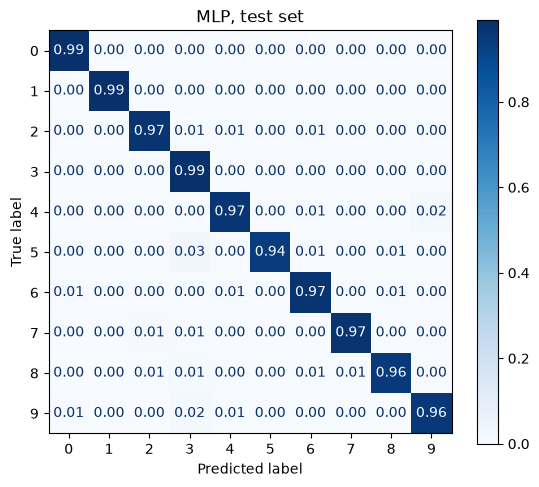

In [17]:
def get_predictions(model, loader, device=DEVICE):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            y_true.append(y)
            y_pred.append(model(x.to(device)).argmax(dim=1).cpu())
    return torch.cat(y_true), torch.cat(y_pred)


def plot_confusion_matrix(model, loader, title):
    y_true, y_pred = get_predictions(model, loader)
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", values_format=".2f")
    ax.set_title(title)
    plt.show()


plot_confusion_matrix(mlp, test_loader, "MLP, test set")

# 8. Same loop, different model: a CNN

Now we check that the loop really is general. The MLP flattens the image as its first step, which throws away the spatial structure: for the MLP two neighbouring pixels are as unrelated as two pixels in opposite corners. A **convolutional network** keeps the image 2D and uses two ideas:

- **local connections**: each unit looks only at a small patch (e.g. $3 \times 3$ pixels), since strokes and edges are local;
- **weight sharing**: the same small filter slides over the whole image, so a stroke detector learned in one place works everywhere.

The building blocks:

- `torch.nn.Conv2d(in_channels, out_channels, kernel_size, padding)`: `out_channels` filters of size `kernel_size` × `kernel_size`, each producing one feature map. With `kernel_size=3, padding=1` height and width are preserved. It has `out_channels × (in_channels × k × k + 1)` parameters, independent of the image size. (See [Conv2d animation](https://poloclub.github.io/cnn-explainer/))
- `torch.nn.MaxPool2d(2)`: keeps the maximum of each $2 \times 2$ block, halving height and width. No parameters.

<p align="center">
  <img src="../notebooks_imgs/conv2d.jpeg" alt="Conv2d on a 3-channel input" width="550"/>
</p>
<p align="center"><sub>Figure: Zhihu user @双手插袋 (知乎).</sub></p>

The figure shows **one** filter applied to an input with 3 channels. The filter has one $3 \times 3$ slice per input channel: each slice slides over its own channel, and the three results are summed (plus a bias) into a single feature map. A `Conv2d` with `out_channels` filters repeats this `out_channels` times. Here there is no padding, so the $5 \times 5$ input becomes a $3 \times 3$ output.

Our CNN has two convolution → ReLU → pooling blocks followed by a linear classifier:

| Layer | Output shape | Parameters |
|---|---|---|
| input | `(batch, 1, 28, 28)` | - |
| `Conv2d(1, 16, 3, padding=1)` + ReLU | `(batch, 16, 28, 28)` | 160 |
| `MaxPool2d(2)` | `(batch, 16, 14, 14)` | 0 |
| `Conv2d(16, 32, 3, padding=1)` + ReLU | `(batch, 32, 14, 14)` | 4,640 |
| `MaxPool2d(2)` | `(batch, 32, 7, 7)` | 0 |
| flatten | `(batch, 1568)` | 0 |
| `Linear(1568, 10)` | `(batch, 10)` | 15,690 |

Input and output shapes are the same as the MLP's, so it satisfies the same contract and the loop will not notice the difference.

**Exercise.** Complete the `CNN` following the table.

In [18]:
class CNN(torch.nn.Module):
    def __init__(self, n_filters1=16, n_filters2=32, out_features=10):
        super().__init__()
        self.conv1 = torch.nn.Conv2d(1, n_filters1, kernel_size=3, padding=1)
        self.conv2 = torch.nn.Conv2d(n_filters1, n_filters2, kernel_size=3, padding=1)
        self.pool = torch.nn.MaxPool2d(kernel_size=2)
        self.activation = torch.nn.ReLU()
        self.classifier = torch.nn.Linear(n_filters2 * 7 * 7, out_features)

    def forward(self, x):
        x = self.pool(self.activation(self.conv1(x)))   # (batch, 16, 14, 14)
        x = self.pool(self.activation(self.conv2(x)))   # (batch, 32, 7, 7)
        x = x.reshape(x.shape[0], -1)                   # (batch, 1568)
        return self.classifier(x)                       # (batch, 10)


cnn = CNN().to(DEVICE)
print("output shape:", cnn(torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE)).shape)
print(f"CNN parameters: {count_parameters(cnn):,}   MLP parameters: {count_parameters(mlp):,}")

output shape: torch.Size([32, 10])
CNN parameters: 20,490   MLP parameters: 55,050


**Exercise.** Train the CNN with exactly the same data, loss, optimizer settings and number of epochs as the MLP. Compared with section 7, only the model line and the optimizer line change, and the optimizer only because it has to receive the parameters of the new model.

In [19]:
torch.manual_seed(0)
cnn = CNN().to(DEVICE)                                                    # 2. model (the only real change)
optimizer = torch.optim.SGD(cnn.parameters(), lr=1e-2, momentum=0.9)      # 4. optimizer, on the CNN's parameters

cnn_history = fit(cnn, train_loader, loss_fn, optimizer, N_EPOCHS, val_loader)

cnn_test_loss, cnn_test_acc = evaluate(cnn, test_loader, loss_fn)
print(f"\nCNN test loss {cnn_test_loss:.4f}  test accuracy {cnn_test_acc:.4f}")

epoch 1/5  train loss 0.1543  val loss 0.0788  val acc 0.9762
epoch 2/5  train loss 0.0569  val loss 0.0542  val acc 0.9828
epoch 3/5  train loss 0.0427  val loss 0.0490  val acc 0.9864
epoch 4/5  train loss 0.0339  val loss 0.0430  val acc 0.9882
epoch 5/5  train loss 0.0281  val loss 0.0413  val acc 0.9898

CNN test loss 0.0311  test accuracy 0.9890


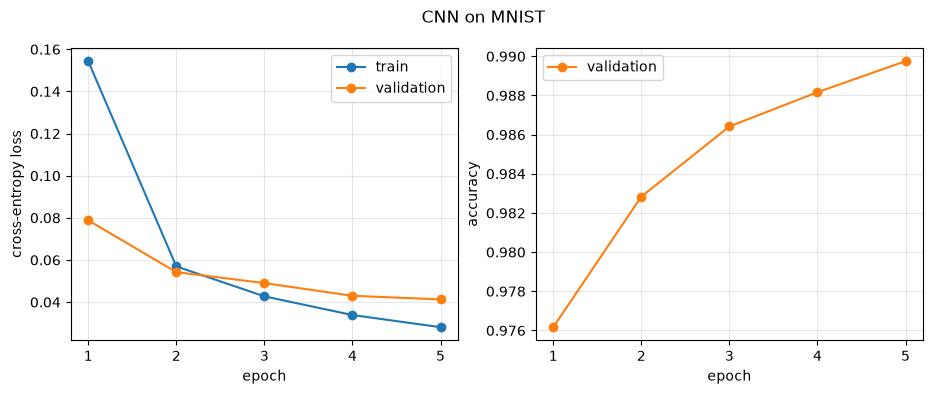

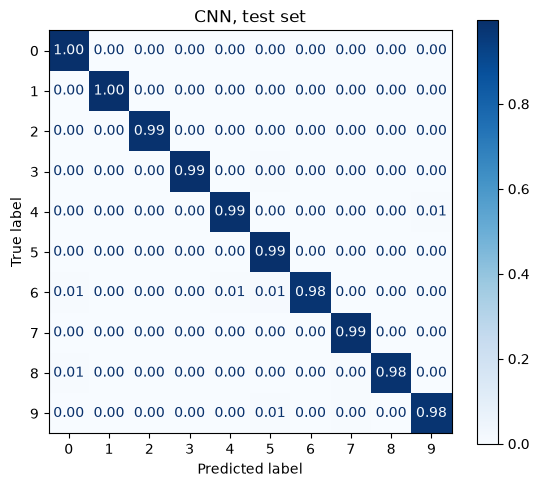

MLP:  55,050 parameters, test accuracy 0.9714
CNN:  20,490 parameters, test accuracy 0.9890


In [20]:
plot_history(cnn_history, "CNN on MNIST")
plot_confusion_matrix(cnn, test_loader, "CNN, test set")

print(f"MLP: {count_parameters(mlp):>7,} parameters, test accuracy {mlp_test_acc:.4f}")
print(f"CNN: {count_parameters(cnn):>7,} parameters, test accuracy {cnn_test_acc:.4f}")

The CNN should beat the MLP with about 2.5 times fewer parameters. Its structure (local filters shared across the image) is a better fit for images than an MLP that treats every pixel independently.

# 9. Hyperparameter tuning of the MLP

So far we picked the learning rate and the hidden sizes by hand. These are **hyperparameters**: values that the training loop does not learn but that we have to choose. The standard recipe is:

1. pick a set of candidate values for each hyperparameter;
2. for every combination, train a model on the training set and measure it on the **validation** set;
3. keep the combination with the best validation accuracy;
4. retrain it on training + validation and evaluate it **once** on the test set.

The test set never takes part in the choice. If we picked the hyperparameters that do best on the test set, the test accuracy would no longer be an honest estimate of performance on new data.

Since `fit` already takes everything as arguments, a grid search is just two nested loops around it. We tune the learning rate and the width of the hidden layers (the same for both layers), with 3 values each: 9 trainings. To keep it fast we train for 3 epochs only; the ranking of the configurations is usually already clear by then. Even so, the cell takes about 5 minutes on a GPU.

**Exercise.** Complete the grid search: for each combination, create a fresh `MLP` and optimizer, train it with `fit` (use `verbose=False`), and store the last validation accuracy in `results`.

In [ ]:
learning_rates = [1e-3, 1e-2]
widths = [32, 128]
TUNING_EPOCHS = 3


def hyperparam_tuning(train_set: torch.utils.data.Dataset, n_splits: int = 5):
    """K-fold grid search over (lr, width).

    Returns a dict (lr, width) -> {"accs", "mean", "var", "std"} with the per-fold
    validation accuracies after the last epoch and their statistics, plus the best
    (lr, width) chosen by the mean accuracy.
    """
    fold_accs = defaultdict(list)   # (lr, width) -> [val acc of fold 0, fold 1, ...]
    grid = list(itertools.product(learning_rates, widths)) # parameters grid (lr, width)

    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    # k-fold loop
    for fold, (train_idx, val_idx) in enumerate(kfold.split(np.arange(len(train_set)))):
        train_subset = Subset(train_set, train_idx)
        val_subset = Subset(train_set, val_idx)

        # parameters combination loop
        for lr, width in grid:

            # same shuffling order and same init for every configuration of a fold
            torch.manual_seed(0)
            # dataloader definition
            train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                                      generator=torch.Generator().manual_seed(fold))
            val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
            # model and optimizer definition
            model = MLP(hidden1=width, hidden2=width).to(DEVICE)
            optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
            # model fit
            history = fit(model, train_loader, loss_fn, optimizer, TUNING_EPOCHS, val_loader, verbose=False)
            # save results
            acc = history["val_acc"][-1]
            fold_accs[(lr, width)].append(acc)

    results = {}
    for key, accs in fold_accs.items():
        accs = np.array(accs)
        results[key] = {"accs": accs, "mean": accs.mean(), "var": accs.var(ddof=1), "std": accs.std(ddof=1)}

    print("\nlr      width  mean acc ± std    (var)")
    for (lr, width), r in sorted(results.items(), key=lambda kv: kv[1]["mean"], reverse=True):
        print(f"{lr:<6g}  {width:<5d}  {r['mean']:.4f} ± {r['std']:.4f}  ({r['var']:.2e})")

    best_lr, best_width = max(results, key=lambda k: results[k]["mean"])
    best = results[(best_lr, best_width)]
    print(f"\nbest: lr={best_lr:g}, width={best_width}, val acc {best['mean']:.4f} ± {best['std']:.4f}")
    return results, best_lr, best_width


# k-fold on all the training data: each fold holds out its own validation part
results, best_lr, best_width = hyperparam_tuning(ConcatDataset([train_set, val_set]), n_splits=5)


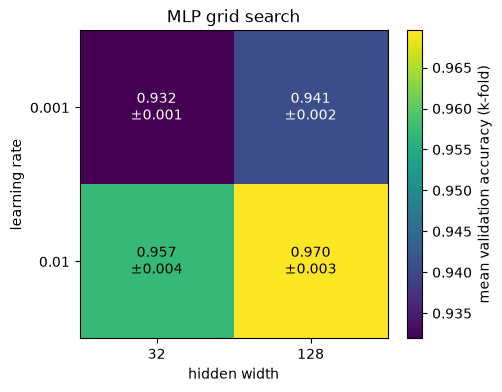

In [23]:
grid = np.array([[results[(lr, w)]["mean"] for w in widths] for lr in learning_rates])
grid_std = np.array([[results[(lr, w)]["std"] for w in widths] for lr in learning_rates])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(grid, cmap="viridis")
ax.set_xticks(range(len(widths)), labels=widths)
ax.set_yticks(range(len(learning_rates)), labels=[f"{lr:g}" for lr in learning_rates])
ax.set_xlabel("hidden width")
ax.set_ylabel("learning rate")
for i in range(len(learning_rates)):
    for j in range(len(widths)):
        ax.text(j, i, f"{grid[i, j]:.3f}\n±{grid_std[i, j]:.3f}", ha="center", va="center",
                color="black" if grid[i, j] > grid.mean() else "white")
fig.colorbar(im, ax=ax, label="mean validation accuracy (k-fold)")
ax.set_title("MLP grid search")
plt.show()


Things to look at in the grid:

- the learning rate matters more than the width. With `lr=1e-1` (and momentum 0.9) the steps are too large, training diverges and the accuracy stays near chance whatever the width;
- with `lr=1e-3` the steps are too small: after 3 epochs every width is still under-trained;
- at a good learning rate wider networks help, but with diminishing returns, while the number of parameters grows quickly (width 512 has about 25 times the parameters of width 32).

The differences between the best few cells can be smaller than the run-to-run noise (try a different seed). A more robust estimate uses **k-fold cross-validation**: split the training data into $k$ parts, train $k$ times each time validating on a different part, and average. It costs $k$ times more; you can implement it with `fit` in the homework.

## Retrain the best MLP and test it

The validation set has done its job, so we merge it back into the training set and retrain the best configuration on all 60k images, this time for the full 5 epochs. Then, and only then, we look at the test set.

In [24]:
full_train_loader = DataLoader(ConcatDataset([train_set, val_set]), batch_size=BATCH_SIZE, shuffle=True)

torch.manual_seed(0)
best_mlp = MLP(hidden1=best_width, hidden2=best_width).to(DEVICE)
optimizer = torch.optim.SGD(best_mlp.parameters(), lr=best_lr, momentum=0.9)
best_history = fit(best_mlp, full_train_loader, loss_fn, optimizer, N_EPOCHS)   # no val_loader

best_test_loss, best_test_acc = evaluate(best_mlp, test_loader, loss_fn)
print()
for name, m, acc in [("MLP (64, 64), lr=0.01", mlp, mlp_test_acc),
                     (f"tuned MLP ({best_width}, {best_width}), lr={best_lr:g}", best_mlp, best_test_acc),
                     ("CNN", cnn, cnn_test_acc)]:
    print(f"{name:32s} {count_parameters(m):>9,} parameters   test accuracy {acc:.4f}")

epoch 1/5  train loss 0.2480
epoch 2/5  train loss 0.0978
epoch 3/5  train loss 0.0685
epoch 4/5  train loss 0.0512
epoch 5/5  train loss 0.0386

MLP (64, 64), lr=0.01               55,050 parameters   test accuracy 0.9714
tuned MLP (128, 128), lr=0.01      118,282 parameters   test accuracy 0.9740
CNN                                 20,490 parameters   test accuracy 0.9890


Tuning improves the MLP by about one point, but in our run it still falls short of the CNN, which has over 30 times fewer parameters. Hyperparameter tuning gets the most out of a model; choosing the right model for the data usually matters more.

# Homework

1. **FashionMNIST.** [FashionMNIST](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) has the same format as MNIST (28×28 grayscale, 10 classes), but the images are clothes. Run the whole pipeline on it. Which blocks of the plan do you have to change? (Hint: only one, plus computing its own normalization values.) How does the accuracy compare with MNIST, and which classes are confused most?

2. **A better `fit`.** Extend `fit` so that it keeps a copy of the weights of the epoch with the best validation accuracy (`copy.deepcopy(model.state_dict())`) and loads them back at the end (`model.load_state_dict(...)`). Optionally add early stopping: stop if the validation accuracy has not improved for `patience` epochs.

3. **More hyperparameters.** Add the batch size (`make_loaders` makes this easy) and the optimizer (`SGD` vs `Adam`) to the grid search. How many trainings does the grid need now? Then replace the single validation split with 3-fold cross-validation, using `fit` on each fold. Does the best configuration change?